In [1]:
# K prototype
!pip install kmodes openpyxl pandas numpy matplotlib scikit-learn


[notice] A new release of pip is available: 25.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from kmodes.kprototypes import KPrototypes
from sklearn.preprocessing import StandardScaler

In [3]:
ruta = "EDA_NoRuc_Volun.xlsx"

df = pd.read_excel(ruta)

df.head()

,TIPO_BAJA,TECNOLOGIA,TIPO_DOC,CIUDAD,FECHA_ALTA,FECHA_BAJA,Fecha alta,Fecha baja,Tiempo de vida,Tiempo_de_vida_meses,Rango de tiempo de vida,FORMA_PAGO,forma_pago_consolidada,SUBSCRIBER_ID,CANAL INGRESO INTENCION,MOTIVO DE BAJA,ARPU,RETENIDO
0,VOLUNTARIA,HFC,CEDULA,GUAYAQUIL,2018-05-31,2026-05-14,2018-05-31,2026-05-14 00:00:00,2905,96.833333,> 12 meses,DEBITO CUENTA - CORRIENTE,Debito,10632659123,NaN,Falta de uso,75.99,NO
1,VOLUNTARIA,GPON,CEDULA,SANTO DOMINGO,2022-12-08,2026-01-18,2022-12-08,2026-01-18 00:00:00,1137,37.900000,> 12 meses,Efectivo,Efectivo,1000157144123,Kiosco,Viaje,70.00,NO
2,VOLUNTARIA,HFC,CEDULA,QUITO,2019-10-07,2026-01-08,2019-10-07,2026-01-08 00:00:00,2285,76.166667,> 12 meses,DEBITO TJTA DE CREDITO,Tarjeta,14383796123,NaN,Cierre de Negocio,55.00,NO
3,VOLUNTARIA,GPON,CEDULA,GUAYAQUIL,2024-06-04,2026-04-15,2024-06-04,2026-04-15 00:00:00,680,22.666667,> 12 meses,Efectivo,Efectivo,1000680434123,Inbound,Inconformidad con el Producto,54.00,NO
4,VOLUNTARIA,GPON,CEDULA,QUITO,2024-01-28,2026-05-09,2024-01-28,2026-05-09 00:00:00,832,27.733333,> 12 meses,Cuenta bancaria,Cuenta bancaria,1000543419123,Inbound,Cambio de Proveedor,54.00,NO


In [8]:
col_id = "SUBSCRIBER_ID"
col_tec = "TECNOLOGIA"
col_vida = "Rango de tiempo de vida"
col_pago = "forma_pago_consolidada"
col_arpu = "ARPU"

In [9]:
base = df[[col_id, col_tec, col_vida, col_pago, col_arpu]].copy()

for col in [col_tec, col_vida, col_pago]:
    base[col] = (
        base[col]
        .astype(str)
        .str.strip()
        .str.upper()
    )

base[col_arpu] = pd.to_numeric(base[col_arpu], errors="coerce")

base = base.dropna(subset=[col_tec, col_vida, col_pago, col_arpu]).copy()

base.head()

,SUBSCRIBER_ID,TECNOLOGIA,Rango de tiempo de vida,forma_pago_consolidada,ARPU
0,10632659123,HFC,> 12 MESES,DEBITO,75.99
1,1000157144123,GPON,> 12 MESES,EFECTIVO,70.00
2,14383796123,HFC,> 12 MESES,TARJETA,55.00
3,1000680434123,GPON,> 12 MESES,EFECTIVO,54.00
4,1000543419123,GPON,> 12 MESES,CUENTA BANCARIA,54.00


In [10]:
scaler = StandardScaler()

base["ARPU_Z"] = scaler.fit_transform(base[[col_arpu]])

base[[col_arpu, "ARPU_Z"]].describe()

,ARPU,ARPU_Z
count,12818.000000,1.281800e+04
mean,18.241407,4.257270e-16
std,4.117991,1.000039e+00
min,5.000000,-3.215627e+00
25%,17.000000,-3.014711e-01
50%,17.600000,-1.557633e-01
75%,20.000000,4.270678e-01
max,75.990000,1.402403e+01


In [11]:
X_kproto = base[["ARPU_Z", col_tec, col_vida, col_pago]].copy()

X_kproto.head()

,ARPU_Z,TECNOLOGIA,Rango de tiempo de vida,forma_pago_consolidada
0,14.024032,HFC,> 12 MESES,DEBITO
1,12.569383,GPON,> 12 MESES,EFECTIVO
2,8.926688,HFC,> 12 MESES,TARJETA
3,8.683842,GPON,> 12 MESES,EFECTIVO
4,8.683842,GPON,> 12 MESES,CUENTA BANCARIA


In [12]:
categorical_cols = [1, 2, 3]

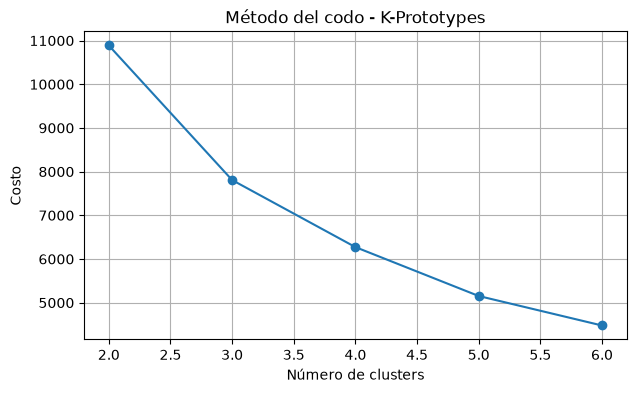

In [13]:
costos = []

rango_k = range(2, 7)

for k in rango_k:
    kp = KPrototypes(
        n_clusters=k,
        init="Huang",
        n_init=10,
        verbose=0,
        random_state=42
    )
    
    clusters = kp.fit_predict(X_kproto, categorical=categorical_cols)
    costos.append(kp.cost_)

plt.figure(figsize=(7,4))
plt.plot(list(rango_k), costos, marker="o")
plt.xlabel("Número de clusters")
plt.ylabel("Costo")
plt.title("Método del codo - K-Prototypes")
plt.grid(True)
plt.show()

In [14]:
k_final = 4

kproto_model = KPrototypes(
    n_clusters=k_final,
    init="Huang",
    n_init=10,
    verbose=0,
    random_state=42
)

base["CLUSTER_KPROTOTYPES"] = kproto_model.fit_predict(
    X_kproto,
    categorical=categorical_cols
)

base.head()

,SUBSCRIBER_ID,TECNOLOGIA,Rango de tiempo de vida,forma_pago_consolidada,ARPU,ARPU_Z,CLUSTER_KPROTOTYPES
0,10632659123,HFC,> 12 MESES,DEBITO,75.99,14.024032,3
1,1000157144123,GPON,> 12 MESES,EFECTIVO,70.00,12.569383,3
2,14383796123,HFC,> 12 MESES,TARJETA,55.00,8.926688,3
3,1000680434123,GPON,> 12 MESES,EFECTIVO,54.00,8.683842,3
4,1000543419123,GPON,> 12 MESES,CUENTA BANCARIA,54.00,8.683842,3


In [15]:
perfil_kproto = []

for cluster in sorted(base["CLUSTER_KPROTOTYPES"].unique()):
    temp = base[base["CLUSTER_KPROTOTYPES"] == cluster]
    
    perfil_kproto.append({
        "Cluster": cluster,
        "Clientes": len(temp),
        "Participacion": len(temp) / len(base),
        "Tecnologia_dominante": temp[col_tec].mode()[0],
        "Tiempo_vida_dominante": temp[col_vida].mode()[0],
        "Forma_pago_dominante": temp[col_pago].mode()[0],
        "ARPU_promedio": temp[col_arpu].mean(),
        "ARPU_mediana": temp[col_arpu].median(),
        "ARPU_desv": temp[col_arpu].std()
    })

perfil_kproto = pd.DataFrame(perfil_kproto)

perfil_kproto.sort_values("Clientes", ascending=False)

,Cluster,Clientes,Participacion,Tecnologia_dominante,Tiempo_vida_dominante,Forma_pago_dominante,ARPU_promedio,ARPU_mediana,ARPU_desv
1,1,5868,0.457794,GPON,> 12 MESES,EFECTIVO,19.686471,20.0,1.822138
2,2,4493,0.350523,GPON,> 12 MESES,CUENTA BANCARIA,16.688276,17.0,1.133633
0,0,1392,0.108597,GPON,> 12 MESES,EFECTIVO,10.764907,10.0,1.352844
3,3,1065,0.083086,GPON,> 12 MESES,EFECTIVO,26.603728,26.0,3.650003


In [16]:
pd.crosstab(
    base["CLUSTER_KPROTOTYPES"],
    base[col_tec],
    normalize="index"
).round(3)

TECNOLOGIA,GPON,HFC
CLUSTER_KPROTOTYPES,,
0,0.802,0.198
1,0.819,0.181
2,0.862,0.138
3,0.820,0.180


In [17]:
pd.crosstab(
    base["CLUSTER_KPROTOTYPES"],
    base[col_vida],
    normalize="index"
).round(3)

Rango de tiempo de vida,0-3 MESES,4-6 MESES,7-12 MESES,> 12 MESES,RETENIDO
CLUSTER_KPROTOTYPES,,,,,
0,0.097,0.045,0.073,0.785,0.000
1,0.026,0.010,0.025,0.879,0.061
2,0.088,0.046,0.095,0.771,0.000
3,0.008,0.005,0.016,0.850,0.121


In [19]:
pd.crosstab(
    base["CLUSTER_KPROTOTYPES"],
    base[col_pago],
    normalize="index"
).round(3)

forma_pago_consolidada,CUENTA BANCARIA,DEBITO,EFECTIVO,TARJETA
CLUSTER_KPROTOTYPES,,,,
0,0.256,0.001,0.718,0.025
1,0.211,0.014,0.747,0.028
2,0.811,0.006,0.114,0.070
3,0.309,0.120,0.518,0.053


In [20]:
nombres_cluster_kproto = {
    0: "Segmento de alto valor",
    1: "Cliente maduro de alta concentración",
    2: "Cliente bancarizado de valor medio",
    3: "Baja temprana o intermedia"
}

base["SEGMENTO_KPROTOTYPES"] = base["CLUSTER_KPROTOTYPES"].map(nombres_cluster_kproto)

base.head()

,SUBSCRIBER_ID,TECNOLOGIA,Rango de tiempo de vida,forma_pago_consolidada,ARPU,ARPU_Z,CLUSTER_KPROTOTYPES,SEGMENTO_KPROTOTYPES
0,10632659123,HFC,> 12 MESES,DEBITO,75.99,14.024032,3,Baja temprana o intermedia
1,1000157144123,GPON,> 12 MESES,EFECTIVO,70.00,12.569383,3,Baja temprana o intermedia
2,14383796123,HFC,> 12 MESES,TARJETA,55.00,8.926688,3,Baja temprana o intermedia
3,1000680434123,GPON,> 12 MESES,EFECTIVO,54.00,8.683842,3,Baja temprana o intermedia
4,1000543419123,GPON,> 12 MESES,CUENTA BANCARIA,54.00,8.683842,3,Baja temprana o intermedia


In [21]:
tabla_presentacion_kproto = (
    base
    .groupby("SEGMENTO_KPROTOTYPES")
    .agg(
        Clientes=(col_id, "count"),
        ARPU_promedio=(col_arpu, "mean"),
        ARPU_mediana=(col_arpu, "median"),
        ARPU_desv=(col_arpu, "std")
    )
    .reset_index()
)

tabla_presentacion_kproto["Participacion"] = (
    tabla_presentacion_kproto["Clientes"] /
    tabla_presentacion_kproto["Clientes"].sum()
)

tabla_presentacion_kproto = tabla_presentacion_kproto.sort_values(
    "Clientes",
    ascending=False
)

tabla_presentacion_kproto

,SEGMENTO_KPROTOTYPES,Clientes,ARPU_promedio,ARPU_mediana,ARPU_desv,Participacion
2,Cliente maduro de alta concentración,5868,19.686471,20.0,1.822138,0.457794
1,Cliente bancarizado de valor medio,4493,16.688276,17.0,1.133633,0.350523
3,Segmento de alto valor,1392,10.764907,10.0,1.352844,0.108597
0,Baja temprana o intermedia,1065,26.603728,26.0,3.650003,0.083086


In [22]:
base.to_excel("base_segmentada_kprototypes.xlsx", index=False)
tabla_presentacion_kproto.to_excel("resumen_segmentos_kprototypes.xlsx", index=False)